# 01 补贴增量效果与定向投放

**问题**：有限金币名额如何优先给真正因补贴而增加活跃的用户？本实验全部为合成数据。随机分组识别总体因果效应，潜在结果仅在模拟器中可见。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from IPython.display import display
plt.style.use('seaborn-v0_8-whitegrid')
pd.options.display.float_format='{:.3f}'.format
rng=np.random.default_rng(42); n=12000
X=pd.DataFrame({'activity':rng.normal(size=n),'sensitivity':rng.uniform(size=n),'tenure':rng.uniform(size=n)})
p0=1/(1+np.exp(-(-.4+.9*X.activity+.5*X.tenure)))
p1=np.clip(p0+np.clip(.04+.32*X.sensitivity-.08*X.activity,.01,.4),0,.99)
t=rng.binomial(1,.5,n); y=rng.binomial(1,np.where(t,p1,p0))
df=X.assign(treat=t,active=y,p0=p0,p1=p1,uplift=p1-p0)
display(df.head())
print('Randomized ATE:',df.loc[t==1,'active'].mean()-df.loc[t==0,'active'].mean(),'simulated truth:',df.uplift.mean())

,activity,sensitivity,tenure,treat,active,p0,p1,uplift
0,0.305,0.276,0.187,0,0,0.492,0.596,0.104
1,-1.040,0.628,0.196,0,1,0.225,0.549,0.324
2,0.750,0.202,0.412,0,1,0.618,0.663,0.045
3,0.941,0.547,0.318,0,1,0.647,0.787,0.140
4,-1.951,0.771,0.646,1,1,0.138,0.538,0.400


Randomized ATE: 0.19908060202284666 simulated truth: 0.20211389633959229


## 随机化与异质性

处理前特征应基本平衡。自然活跃概率与补贴增量是不同的目标；不能把领取率或活跃预测分数当成增量。

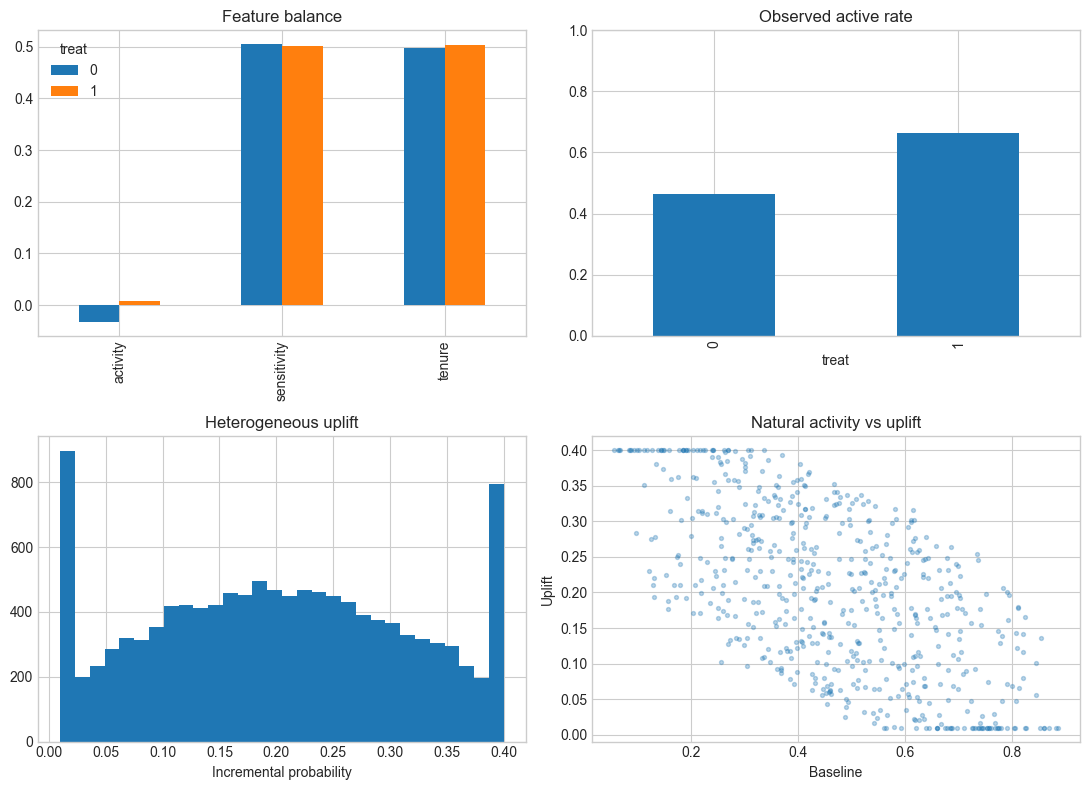

In [2]:
fig,ax=plt.subplots(2,2,figsize=(11,8))
df.groupby('treat')[['activity','sensitivity','tenure']].mean().T.plot.bar(ax=ax[0,0],title='Feature balance')
df.groupby('treat').active.mean().plot.bar(ax=ax[0,1],title='Observed active rate',ylim=(0,1))
ax[1,0].hist(df.uplift,bins=30);ax[1,0].set(title='Heterogeneous uplift',xlabel='Incremental probability')
ax[1,1].scatter(df.p0.iloc[::20],df.uplift.iloc[::20],s=8,alpha=.3);ax[1,1].set(title='Natural activity vs uplift',xlabel='Baseline',ylabel='Uplift')
plt.tight_layout();plt.show()

## T-learner

分别拟合处理组和对照组活跃概率，并在留出的测试集上相减。真实业务还需时间切分、概率校准、泄漏排查。

In [3]:
tr,te=train_test_split(np.arange(n),test_size=.35,random_state=7,stratify=t)
models={}
for a in [0,1]:
    ix=tr[t[tr]==a]
    models[a]=LogisticRegression(max_iter=500).fit(X.iloc[ix],y[ix])
test=df.iloc[te].copy()
test['score']=models[1].predict_proba(X.iloc[te])[:,1]-models[0].predict_proba(X.iloc[te])[:,1]
test['natural']=models[0].predict_proba(X.iloc[te])[:,1]
print('Score-truth correlation:',test[['score','uplift']].corr().iloc[0,1])
display(test[['score','uplift','natural']].describe())

Score-truth correlation: 0.9716571386141032


,score,uplift,natural
count,4200.000,4200.000,4200.000
mean,0.197,0.202,0.463
std,0.128,0.114,0.191
min,-0.103,0.010,0.053
25%,0.104,0.112,0.317
50%,0.191,0.200,0.454
75%,0.289,0.291,0.602
max,0.495,0.400,0.940


## 等预算策略比较

每个名额花费 1 单位。模拟器可计算潜在概率下的期望增量；现实不能直接观察个体真值，应以随机实验验证。

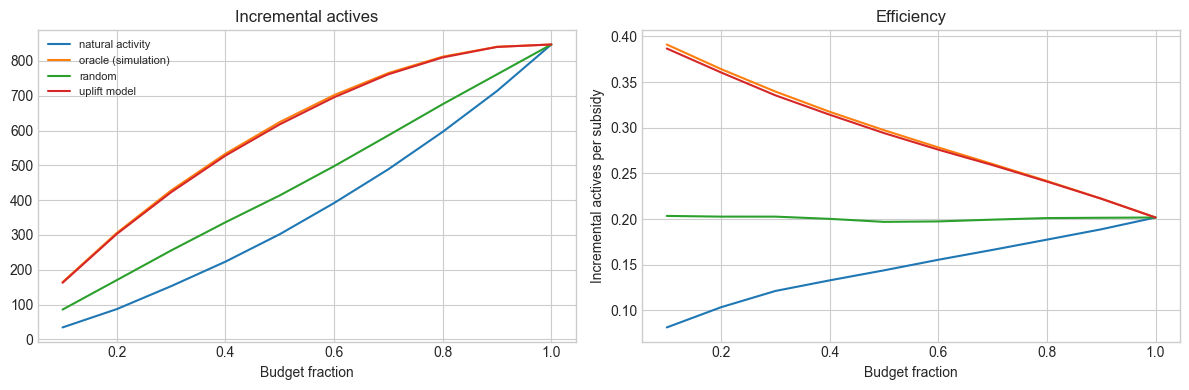

,strategy,budget_fraction,incremental_actives,incremental_per_subsidy
32,oracle (simulation),0.300,427.949,0.340
2,uplift model,0.300,422.738,0.336
22,random,0.300,255.346,0.203
12,natural activity,0.300,152.791,0.121


In [4]:
rows=[]
strategies={'uplift model':test.score.to_numpy(),'natural activity':test.natural.to_numpy(),'random':rng.random(len(test)),'oracle (simulation)':test.uplift.to_numpy()}
for name,score in strategies.items():
    order=np.argsort(-score)
    for frac in np.arange(.1,1.01,.1):
        chosen=order[:int(frac*len(test))]
        rows.append((name,frac,test.uplift.to_numpy()[chosen].sum(),test.uplift.to_numpy()[chosen].mean()))
result=pd.DataFrame(rows,columns=['strategy','budget_fraction','incremental_actives','incremental_per_subsidy'])
fig,ax=plt.subplots(1,2,figsize=(12,4))
for name,g in result.groupby('strategy'):
    ax[0].plot(g.budget_fraction,g.incremental_actives,label=name)
    ax[1].plot(g.budget_fraction,g.incremental_per_subsidy,label=name)
ax[0].set(title='Incremental actives',xlabel='Budget fraction')
ax[1].set(title='Efficiency',xlabel='Budget fraction',ylabel='Incremental actives per subsidy')
ax[0].legend(fontsize=8);plt.tight_layout();plt.show()
display(result[np.isclose(result.budget_fraction,.3)].sort_values('incremental_actives',ascending=False))

## 分桶校准与结论

预测分桶的实验估计存在随机噪声。上线需在同预算下随机比较增量 DAU、7/30 日留存、投诉和成本，并报告置信区间。真实数据至少包括随机组、处理前特征、曝光时间、实际成本及短长期结果。

,predicted,truth,size,experiment
decile,,,,
0,-0.015,0.017,420,0.013
1,0.059,0.072,420,0.137
2,0.103,0.115,420,0.165
3,0.139,0.157,420,0.179
4,0.174,0.185,420,0.226
5,0.208,0.214,420,0.102
6,0.246,0.251,420,0.261
7,0.292,0.285,420,0.176
8,0.346,0.334,420,0.335


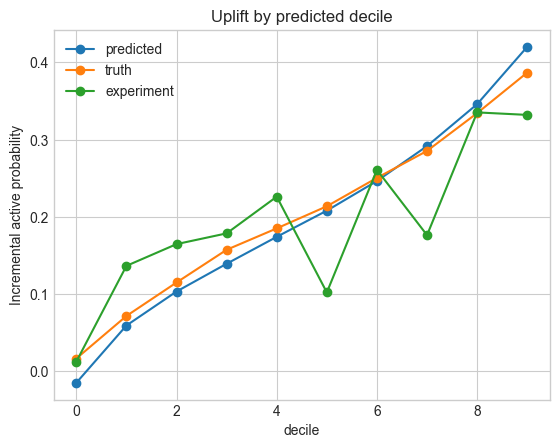

In [5]:
test['decile']=pd.qcut(test.score,10,labels=False,duplicates='drop')
g=test.groupby('decile').agg(predicted=('score','mean'),truth=('uplift','mean'),size=('active','size'))
obs=test.groupby(['decile','treat']).active.mean().unstack()
g['experiment']=obs[1]-obs[0]
display(g)
g[['predicted','truth','experiment']].plot(marker='o',title='Uplift by predicted decile',ylabel='Incremental active probability')
plt.show()